# Mutational Signature Analysis Example

This notebook demonstrates the mutational signature analysis visualizations. Somatic SNVs arise from different mutational processes (aging, UV exposure, APOBEC activity, etc.), each leaving a characteristic pattern across 96 trinucleotide mutation contexts.

For detailed documentation, see the [Mutational Signature Analysis API Reference](https://luisruimor.github.io/pyMut/api/Visualization/mutational_signature_analysis/).

## Load Data

Load the MAF file and create a `PyMutation` object.

In [1]:
from pyMut.input import read_maf

maf_path = "../../../src/pyMut/data/examples/MAF/ms.maf.gz"
print(f'📂 Loading file: {maf_path}')

# Read the MAF file and create the PyMutation object
py_mutation = read_maf(maf_path,assembly="37")


2026-10-13 14:45:55,870 | INFO | pyMut.input | Starting MAF reading: ../../../src/pyMut/data/examples/MAF/ms.maf.gz
2026-10-13 14:45:55,872 | INFO | pyMut.input | Loading from cache: ../../../src/pyMut/data/examples/MAF/.pymut_cache/ms.maf_dd4530060d7dcebf.parquet


📂 Loading file: ../../../src/pyMut/data/examples/MAF/ms.maf.gz


2026-10-13 14:45:56,206 | INFO | pyMut.input | Cache loaded successfully in 0.34 seconds


## Configure Plot Settings

Enable high-quality rendering settings for publication-ready figures.

In [2]:
py_mutation.configure_high_quality_plots()


## Complete Mutational Signature Analysis

The `mutational_signature_analysis()` function generates a comprehensive five-panel figure:

- **Panel A**: Signature profiles showing trinucleotide distribution for each signature
- **Panel B**: Cosine similarity heatmap comparing extracted signatures with COSMIC
- **Panel C**: Heatmap of relative signature contributions per sample
- **Panel D**: Stacked bar chart of signature distribution across samples
- **Panel E**: Donut plot of cohort-level signature proportions

**Key Parameters:**

- `ref_genome`: Path to reference genome FASTA file (required)
- `cosmic_path`: COSMIC catalog identifier or path. Use `None` for bundled official COSMIC v3.4 SBS (GRCh37), `"maftools"` for bundled 67-signature catalog, or a custom TSV path.
- `n_signatures`: Number of signatures to extract. Default: `3`
- `figsize`: Figure size. Default: `(24, 12)`
- `title`: Plot title. Default: `"Mutational Signature Analysis"`


2026-10-13 14:45:57,369 | INFO | pyMut.core | Generating complete mutational signature analysis...
2026-10-13 14:46:03,382 | INFO | rpy2.situation | cffi mode is CFFI_MODE.ANY
2026-10-13 14:46:03,387 | INFO | rpy2.situation | R home found: /home/victor/miniconda3/envs/PyMut_env_validation/lib/R
2026-10-13 14:46:03,607 | INFO | rpy2.situation | R library path: 
2026-10-13 14:46:03,608 | INFO | rpy2.situation | LD_LIBRARY_PATH: 
2026-10-13 14:46:03,622 | INFO | rpy2.rinterface_lib.embedded | Default options to initialize R: rpy2, --quiet, --no-save
2026-10-13 14:46:03,873 | INFO | rpy2.rinterface | Environment variable "PWD" redefined by R and overriding existing variable. Current: "/home/victor", R: "/home/victor/Documentos/Alba/PyMut_validation/docs/examples/visualization"
2026-10-13 14:46:04,069 | INFO | rpy2.rinterface | R is already initialized. No need to initialize.
2026-10-13 14:46:06,233 | INFO | pyMut.analysis.mutational_signature | NMF signature extraction completed in 2.16 se

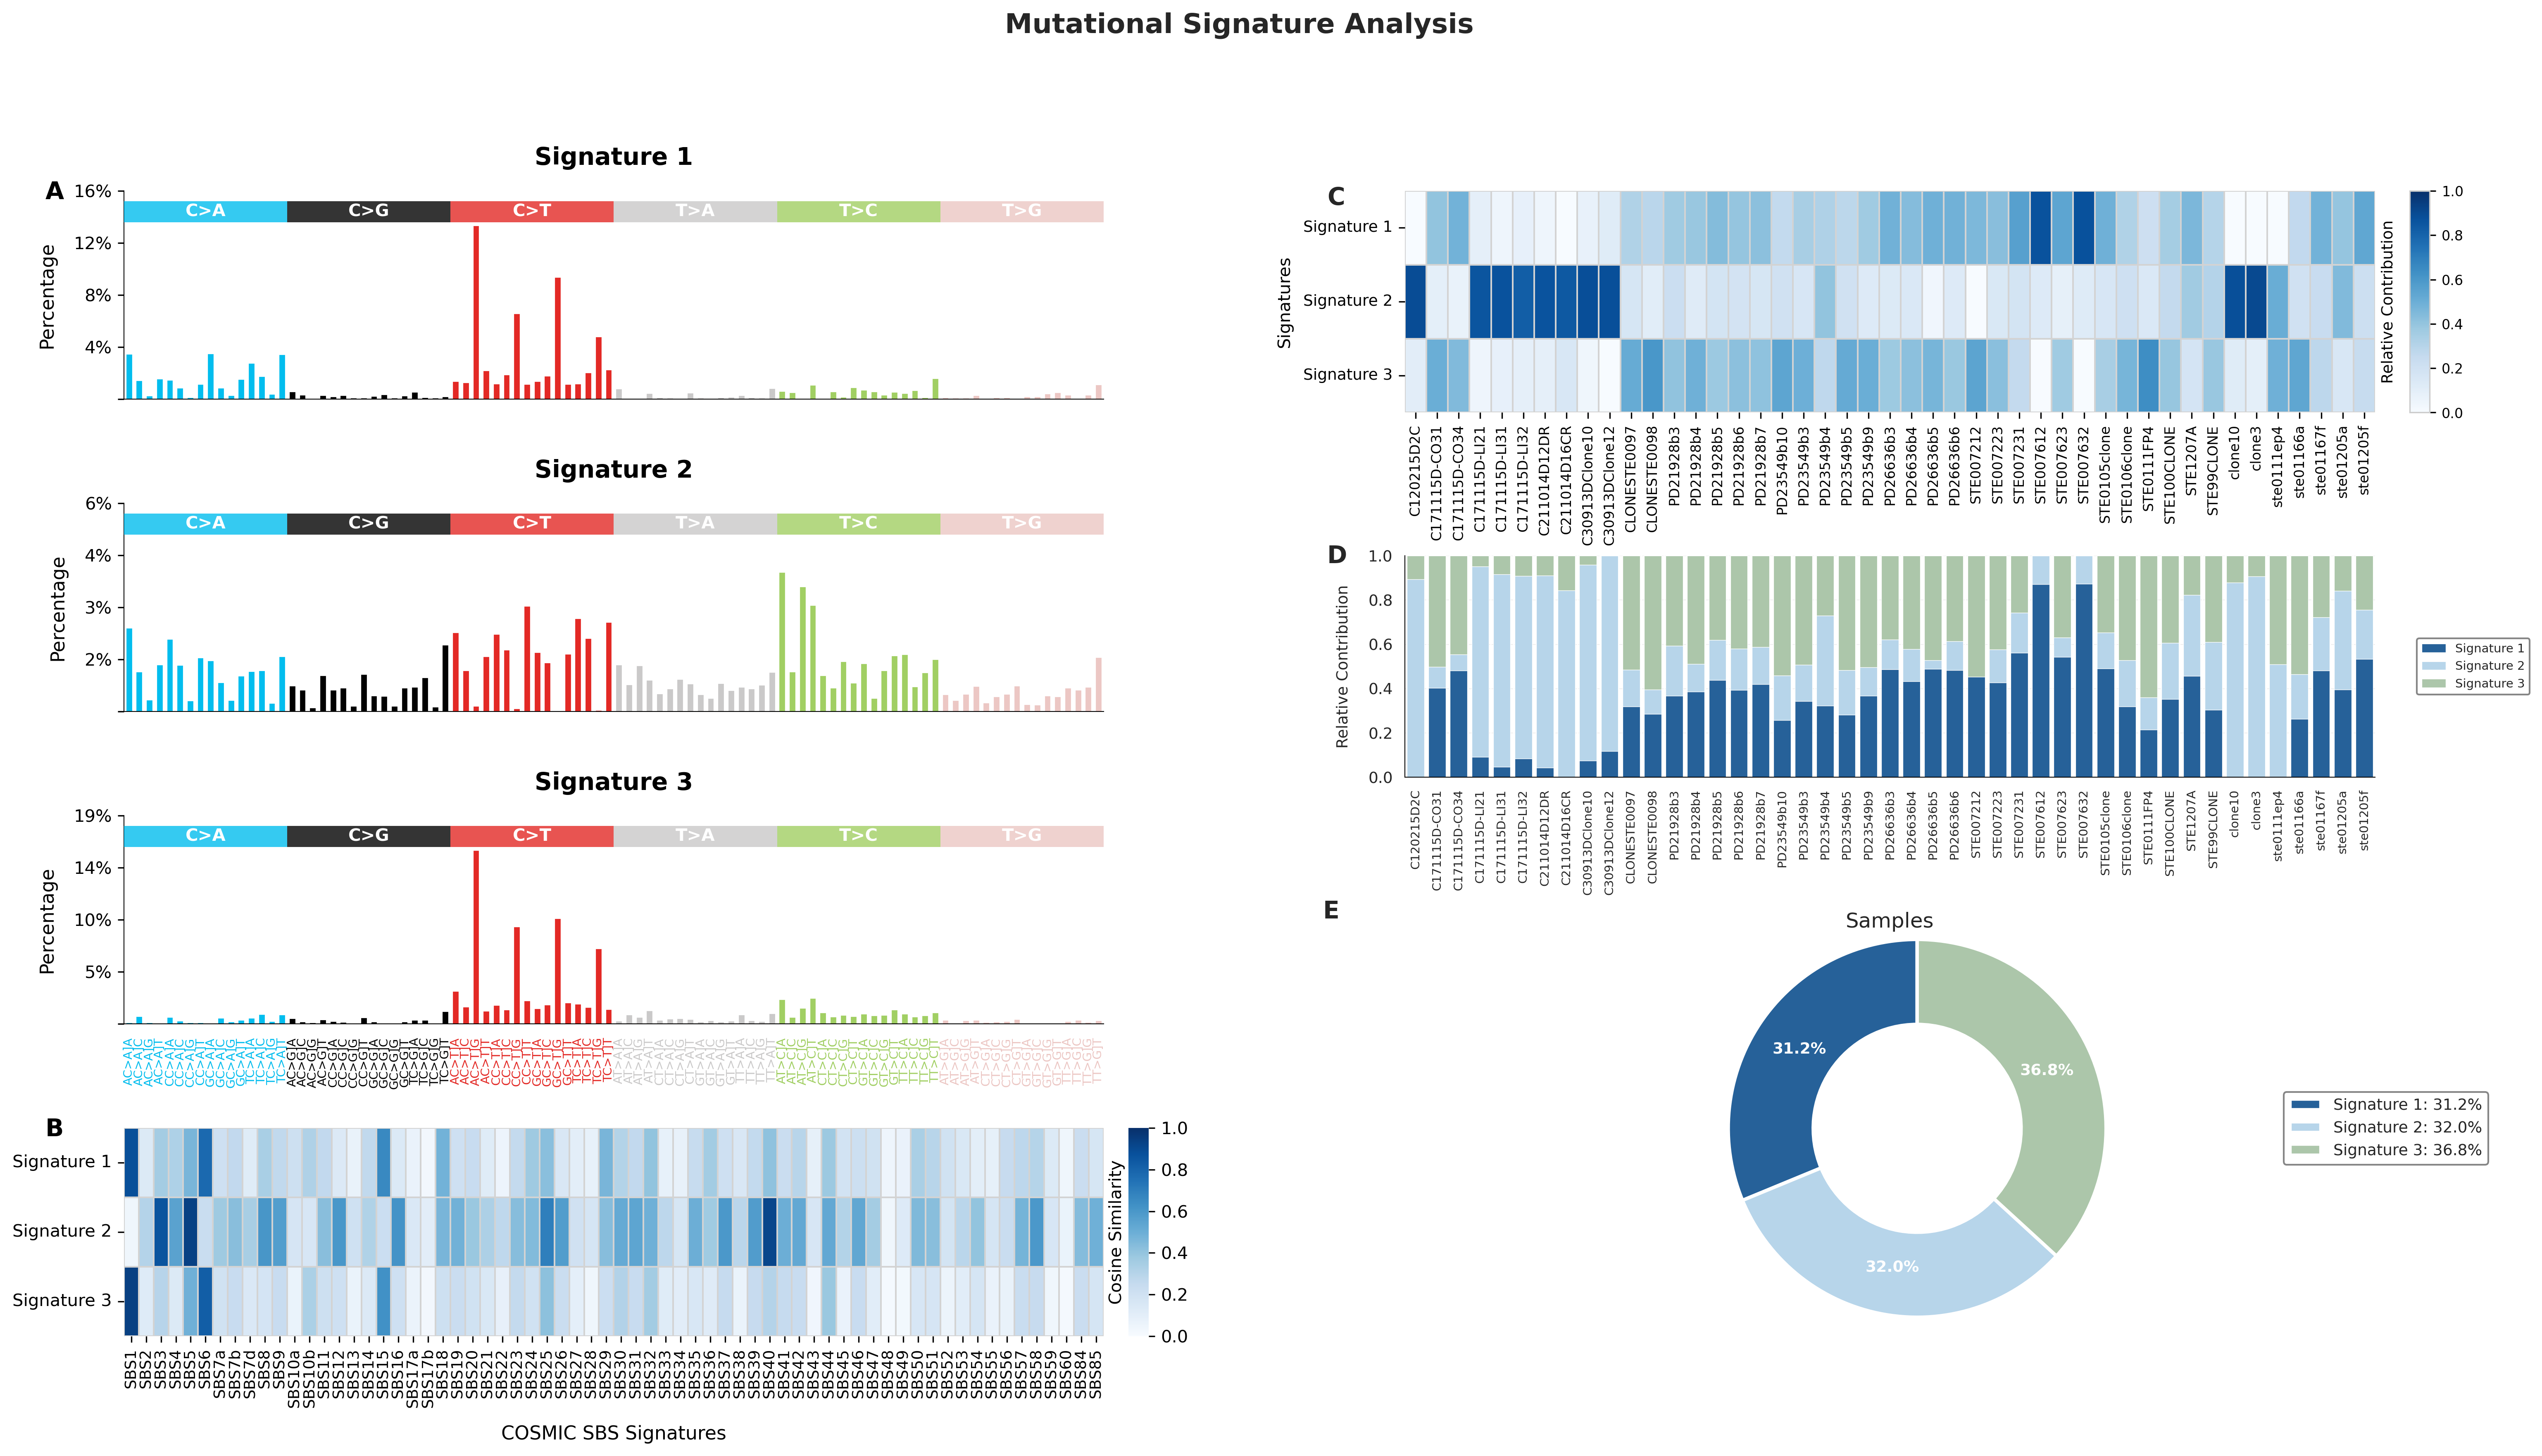

In [3]:
py_mutation.mutational_signature_analysis(
    ref_genome="/home/victor/.local/share/Trash/files/PyMut/data/references/hs37d5.fa",
    cosmic_path="maftools",
)


## Individual Panel Components

Each panel from the complete analysis is also available as a standalone function.

### Panel A: Signature Bar Chart

Multi-panel visualization showing each mutational signature as a bar chart with 96 trinucleotide contexts. Bars are grouped by the 6 substitution classes (C>A, C>G, C>T, T>A, T>C, T>G).

**Parameters:**

- `ref_genome`: Path to reference genome FASTA file (required)
- `n_signatures`: Number of signatures to extract. Default: `3`
- `cosmic_path`: COSMIC catalog. Use `None` (bundled official v3.4), `"maftools"` (bundled 67-sig catalog), custom path, or `False` to skip COSMIC alignment.
- `aetiology_path`: Etiology table path or `"maftools"` (optional).
- `exclude_artifacts`: Whether to exclude sequencing artifacts (default: `True`).
- `figsize`: Figure size. Default: auto-calculated
- `title`: Plot title. Default: `"Mutational Signature Profiles"`


2026-10-13 14:46:09,617 | INFO | pyMut.core | Generating signature bar chart...
2026-10-13 14:46:16,405 | INFO | pyMut.analysis.mutational_signature | NMF signature extraction completed in 0.82 seconds
2026-10-13 14:46:16,410 | INFO | pyMut.analysis.mutational_signature | Aligning extracted signatures with COSMIC catalog...
2026-10-13 14:46:16,411 | INFO | pyMut.analysis.mutational_signature | Comparing 3 signatures with COSMIC catalog
2026-10-13 14:46:16,418 | INFO | pyMut.analysis.mutational_signature | Loaded COSMIC catalog with shape (96, 68)
2026-10-13 14:46:16,420 | INFO | pyMut.analysis.mutational_signature | Aligning COSMIC catalog with standard trinucleotide context order...
2026-10-13 14:46:16,423 | INFO | pyMut.analysis.mutational_signature | COSMIC catalog successfully aligned to standard context order
2026-10-13 14:46:16,423 | INFO | pyMut.analysis.mutational_signature | Removing artifact signature SBS7c (ends with 'c')
2026-10-13 14:46:16,424 | INFO | pyMut.analysis.mutat

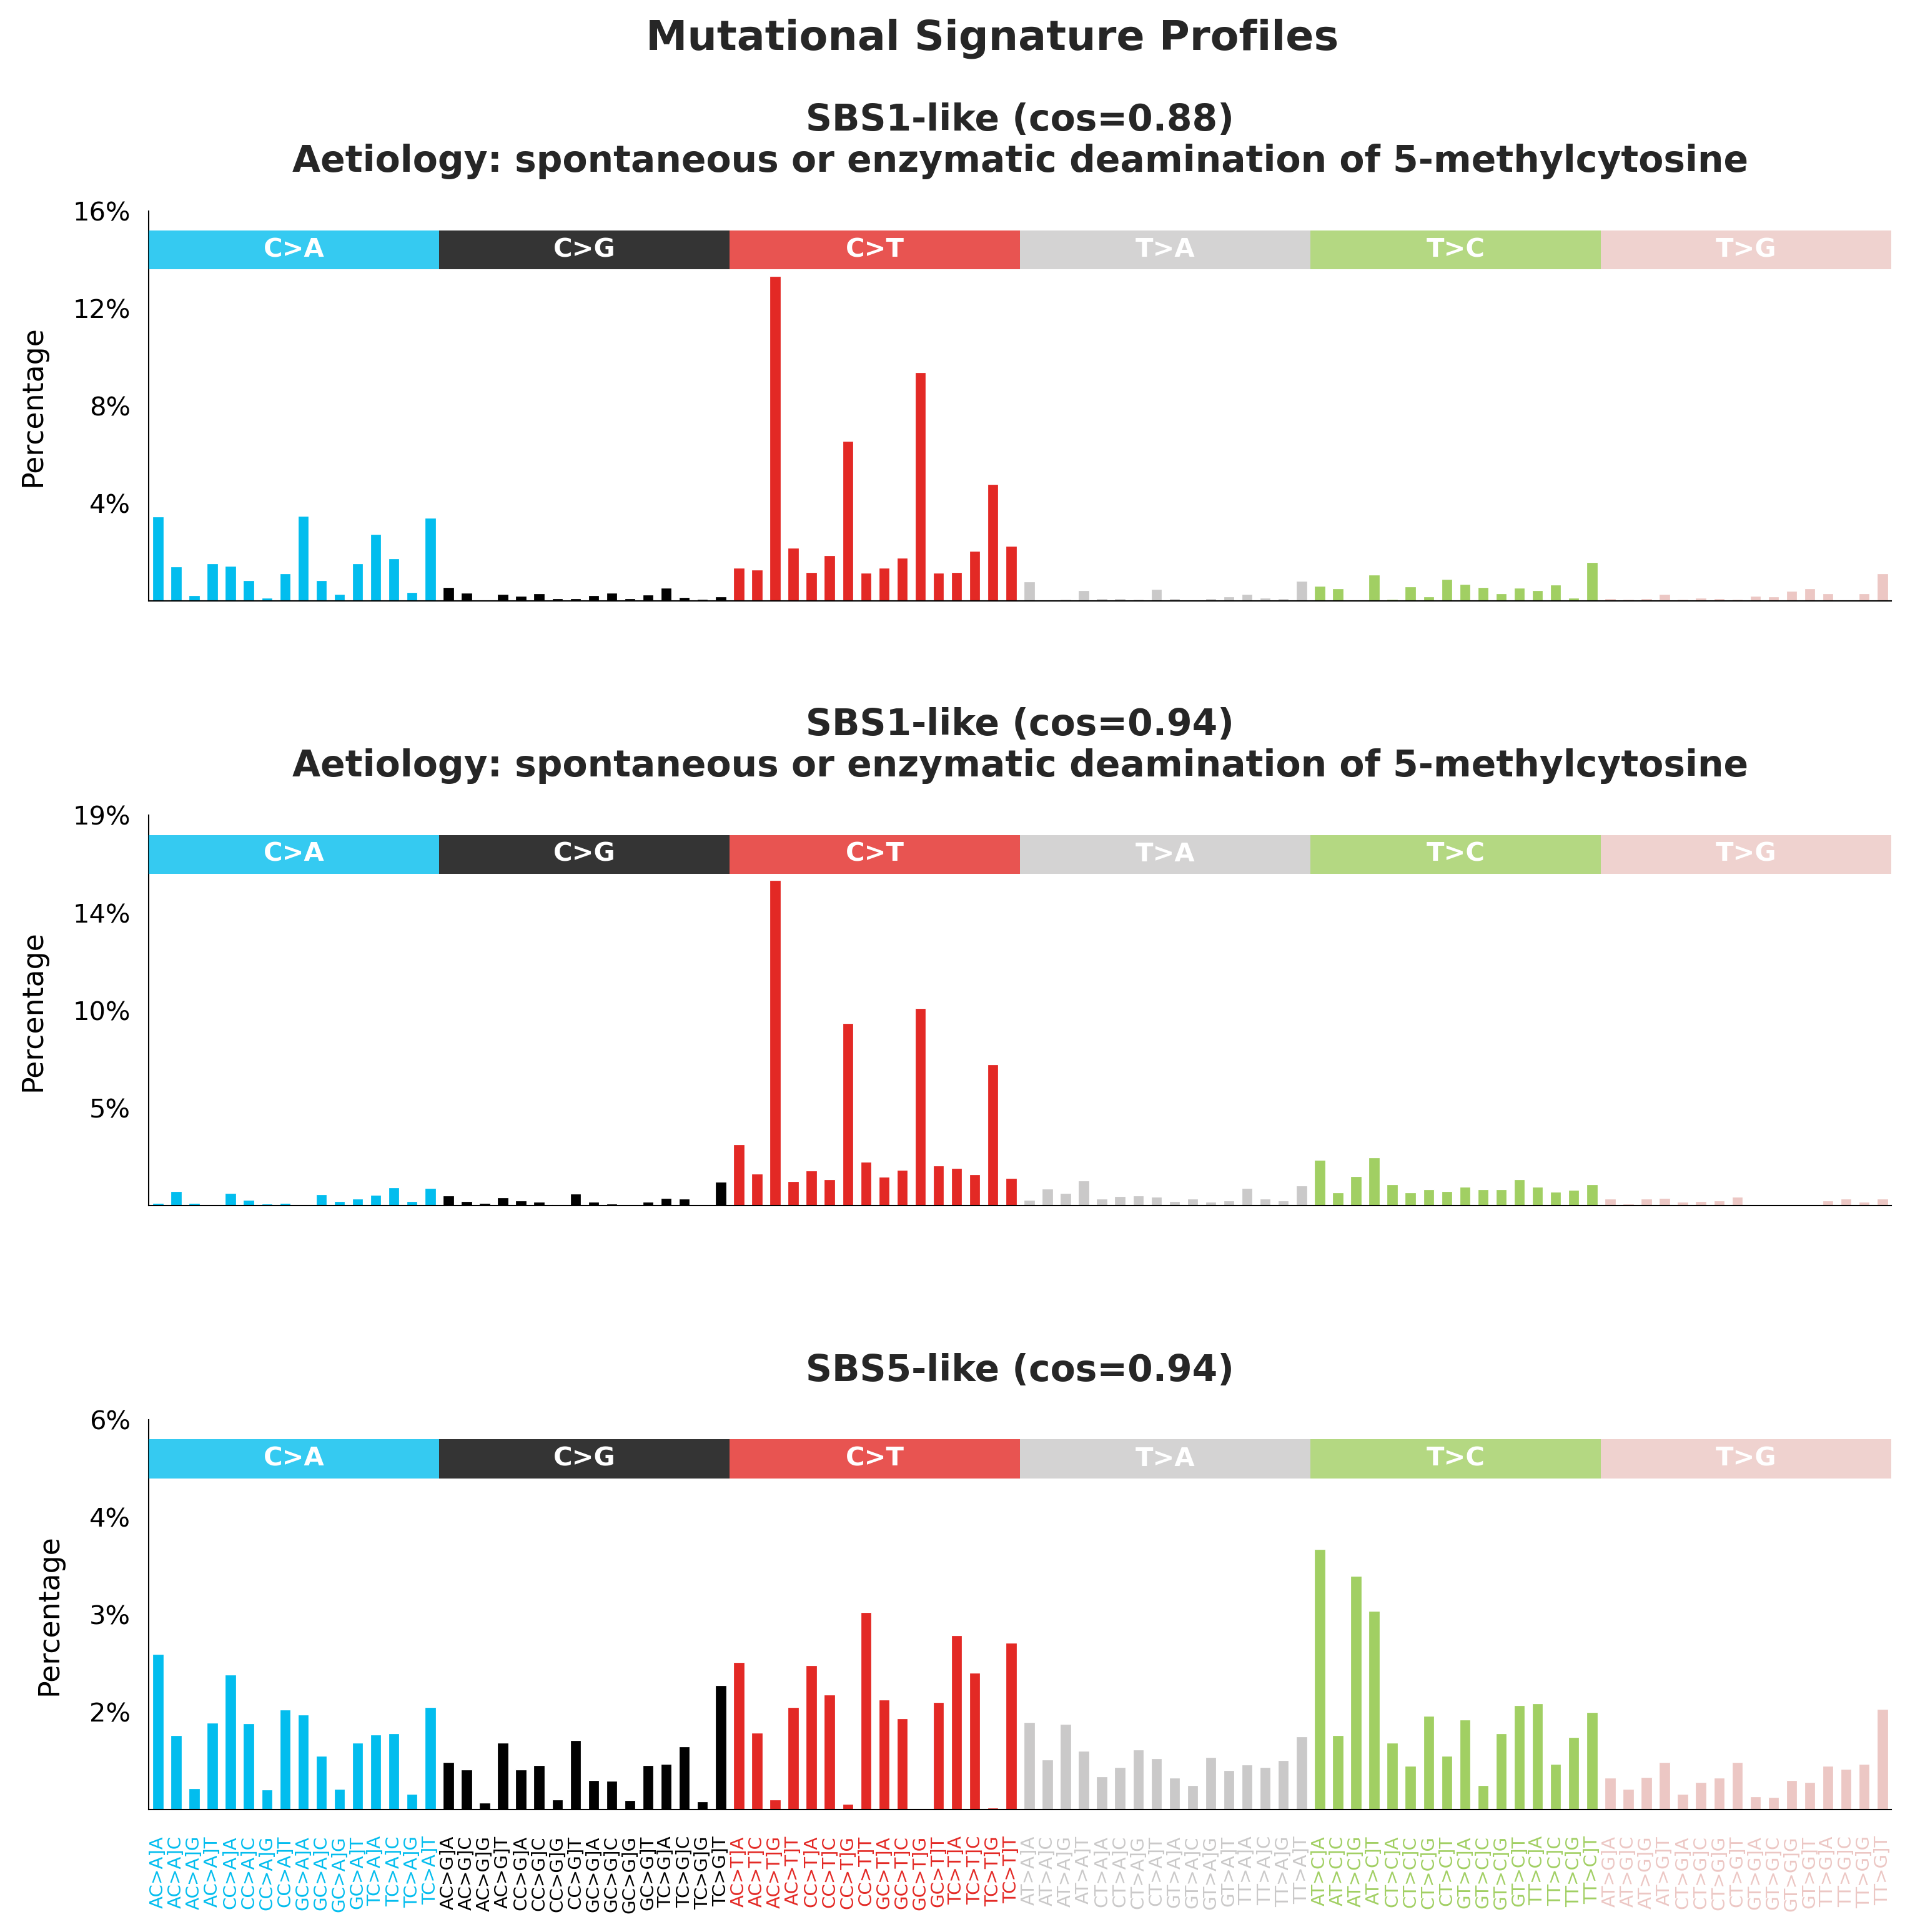

In [4]:
py_mutation.signature_bar_chart(
    ref_genome="/home/victor/.local/share/Trash/files/PyMut/data/references/hs37d5.fa",
    cosmic_path="maftools",
    aetiology_path="maftools",
    exclude_artifacts=True
)


### Panel B: Cosine Similarity Heatmap

Heatmap comparing extracted signatures with the COSMIC catalog of known mutational signatures. High similarity values (≥ 0.85) suggest a close match to a known biological process.

**Parameters:**

- `ref_genome`: Path to reference genome FASTA file (required)
- `cosmic_path`: Path to COSMIC signature catalog (required)
- `n_signatures`: Number of signatures to extract. Default: `3`
- `figsize`: Figure size. Default: `(14, 3)`
- `title`: Plot title. Default: `"Cosine Similarity: Extracted vs COSMIC Signatures"`


2026-10-13 14:46:17,459 | INFO | pyMut.core | Generating cosine similarity heatmap...
2026-10-13 14:46:22,928 | INFO | pyMut.analysis.mutational_signature | NMF signature extraction completed in 0.40 seconds
2026-10-13 14:46:22,932 | INFO | pyMut.visualizations.mutational_signature_analysis | Generating cosine similarity heatmap...
2026-10-13 14:46:23,129 | INFO | pyMut.visualizations.mutational_signature_analysis | Cosine similarity heatmap generated in 0.20s
2026-10-13 14:46:23,147 | INFO | pyMut.core | Cosine similarity heatmap generated in 5.69s


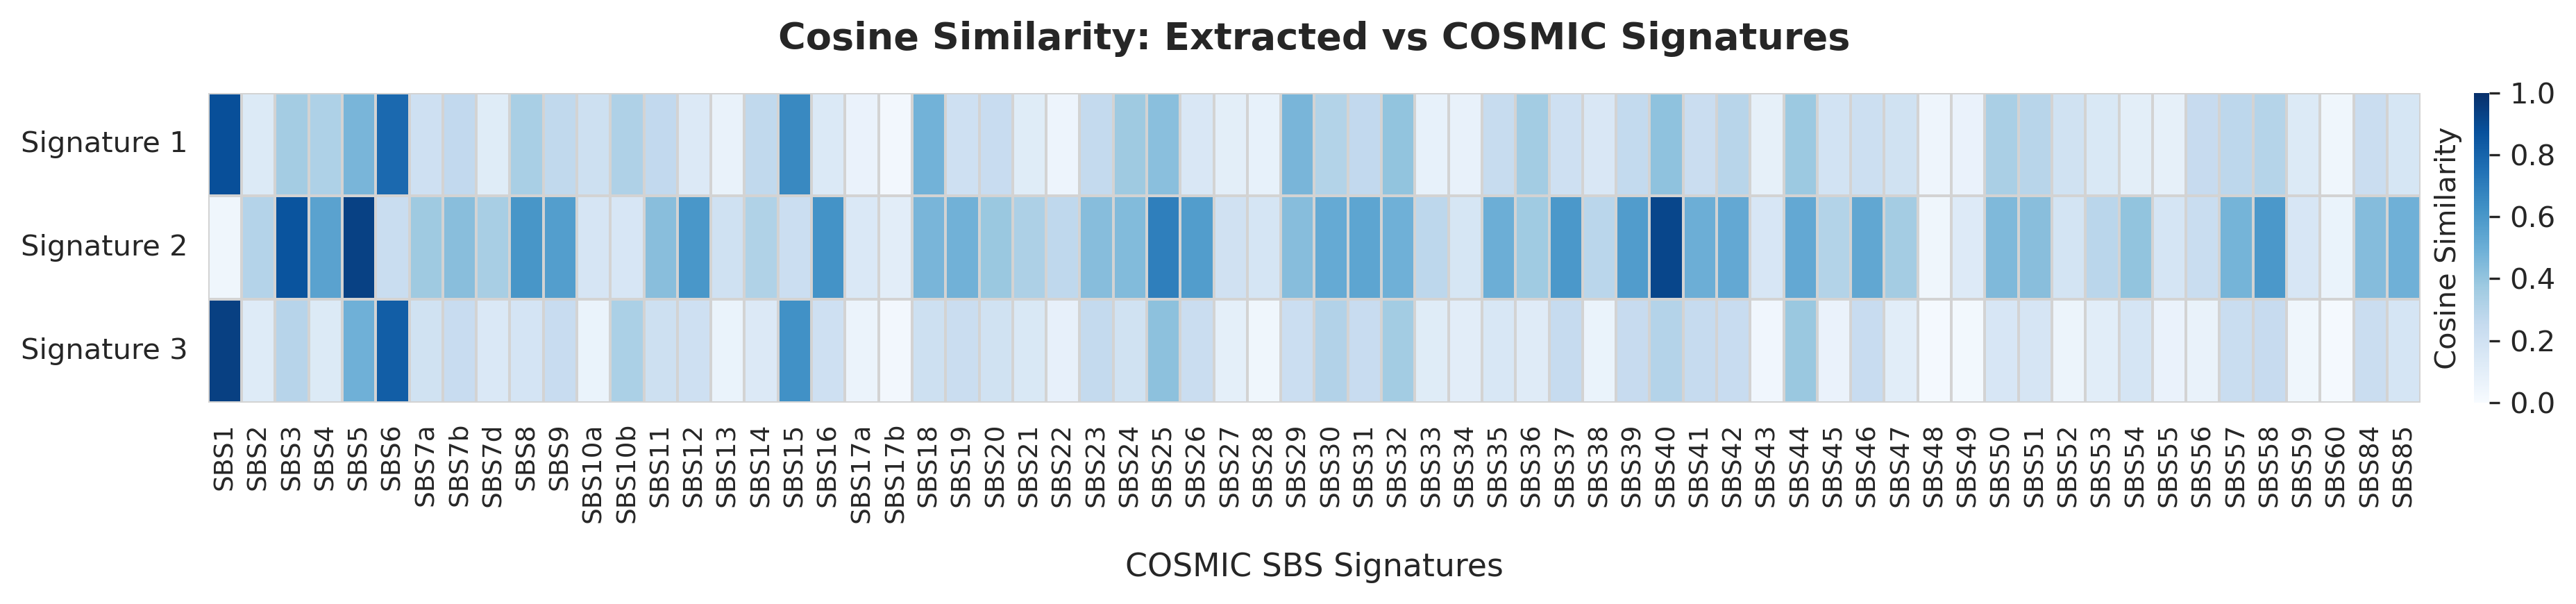

In [5]:
py_mutation.cosine_similarity_heatmap(
    ref_genome="/home/victor/.local/share/Trash/files/PyMut/data/references/hs37d5.fa",
    cosmic_path="maftools",
)


### Panel C: Signature Contribution Heatmap

Heatmap showing the proportion of mutations in each sample attributable to each signature. Values are column-normalized (each sample sums to 1).

**Parameters:**

- `ref_genome`: Path to reference genome FASTA file (required)
- `n_signatures`: Number of signatures to extract. Default: `3`
- `cosmic_path`: Path to COSMIC catalog (optional, for signature alignment)
- `cmap`: Colormap name. Default: `'Blues'`
- `show_values`: Display numerical values in cells. Default: `False`
- `figsize`: Figure size. Default: auto-calculated
- `title`: Plot title. Default: `"Signature Contributions per Sample"`


2026-10-13 14:46:23,446 | INFO | pyMut.core | Generating signature contribution heatmap...
2026-10-13 14:46:29,191 | INFO | pyMut.analysis.mutational_signature | NMF signature extraction completed in 0.39 seconds
2026-10-13 14:46:29,204 | INFO | pyMut.analysis.mutational_signature | Aligning extracted signatures with COSMIC catalog...
2026-10-13 14:46:29,205 | INFO | pyMut.analysis.mutational_signature | Comparing 3 signatures with COSMIC catalog
2026-10-13 14:46:29,215 | INFO | pyMut.analysis.mutational_signature | Loaded COSMIC catalog with shape (96, 87)
2026-10-13 14:46:29,217 | INFO | pyMut.analysis.mutational_signature | Aligning COSMIC catalog with standard trinucleotide context order...
2026-10-13 14:46:29,219 | INFO | pyMut.analysis.mutational_signature | COSMIC catalog successfully aligned to standard context order
2026-10-13 14:46:29,220 | INFO | pyMut.analysis.mutational_signature | Removing artifact signature SBS7c (ends with 'c')
2026-10-13 14:46:29,221 | INFO | pyMut.ana

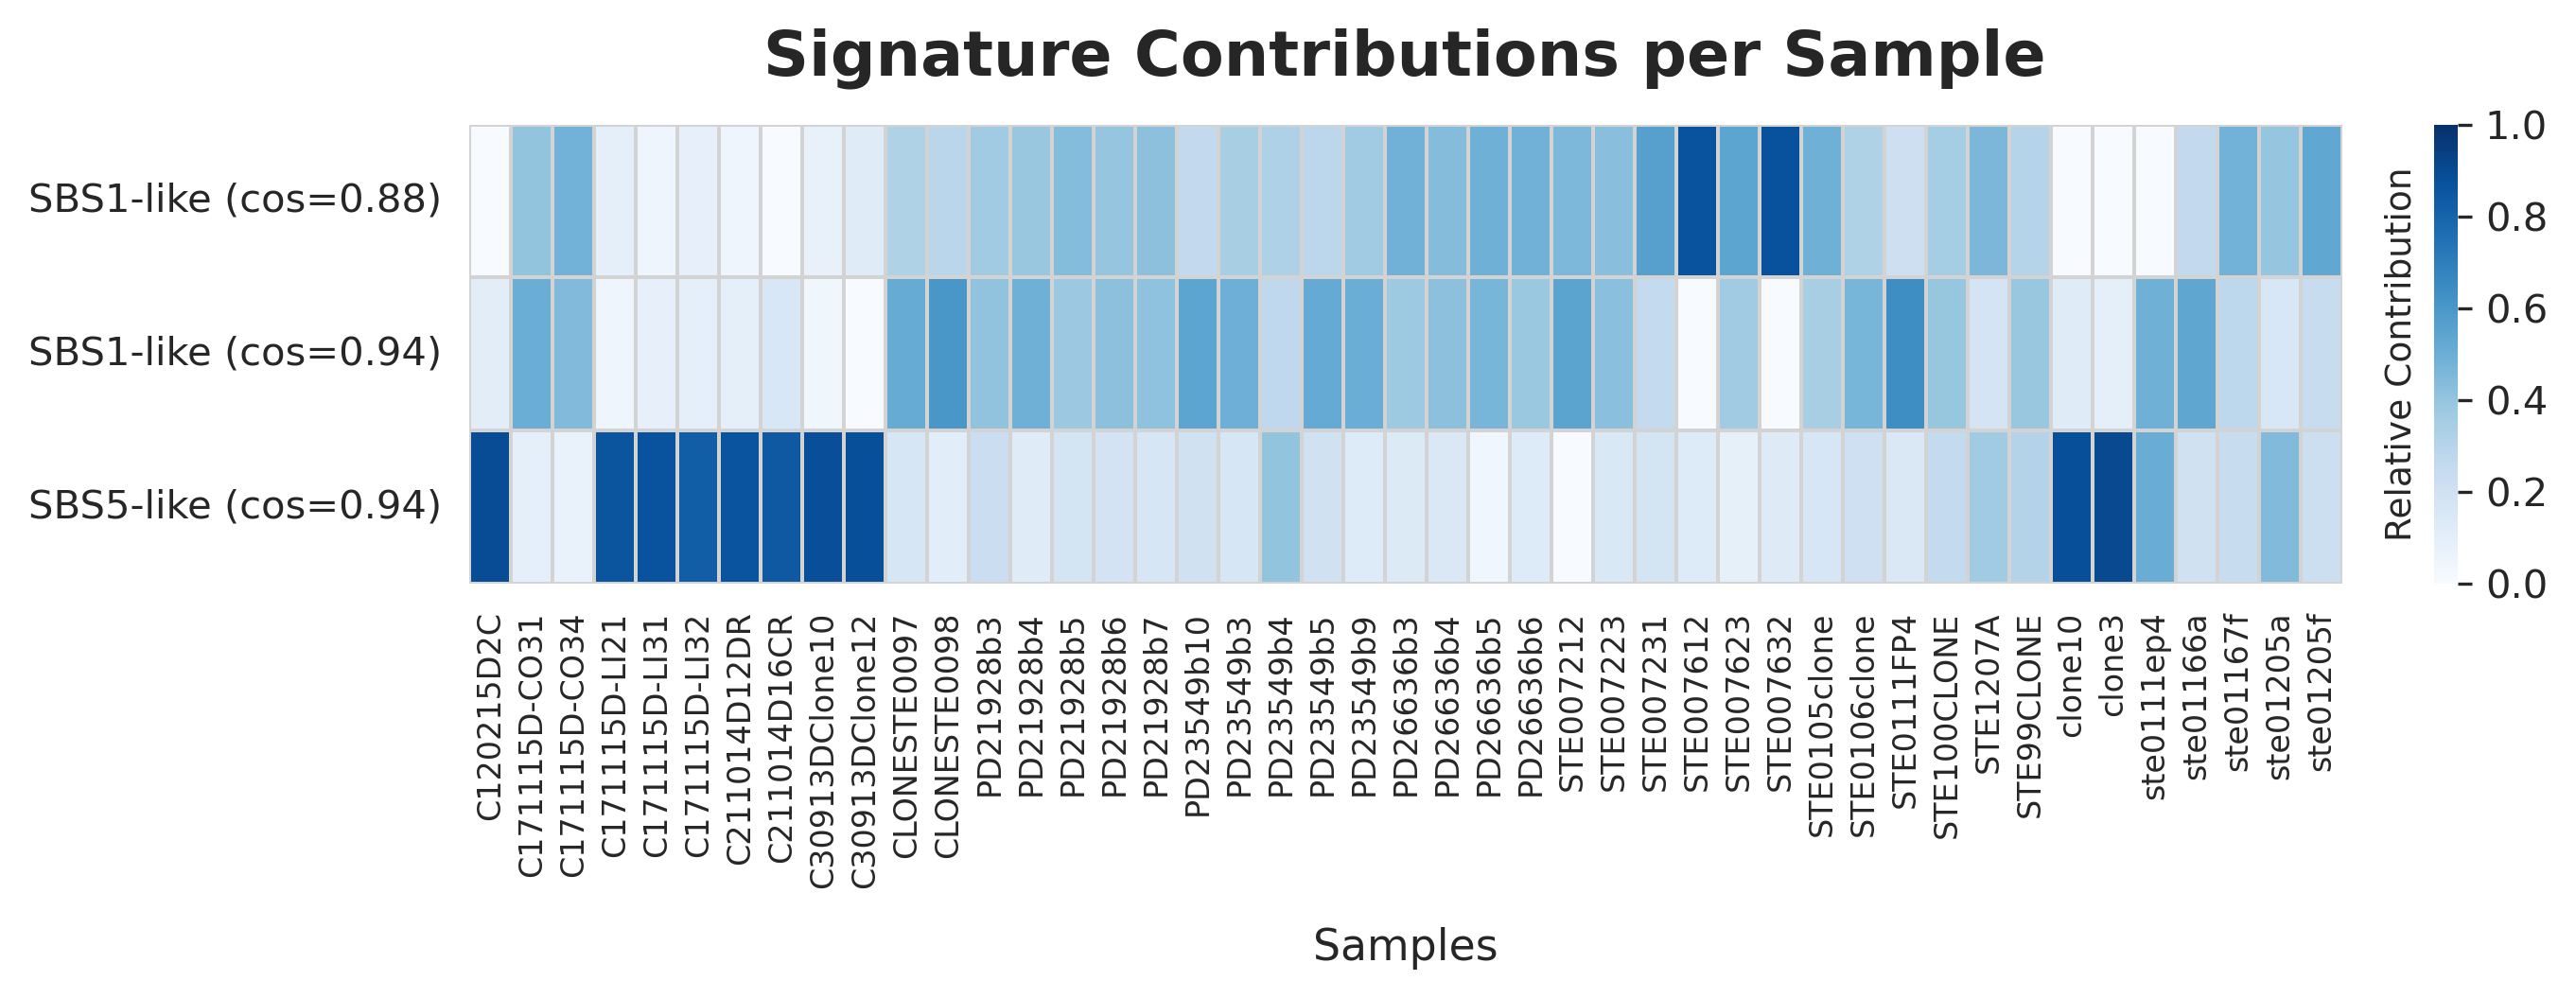

In [6]:
py_mutation.signature_contribution_heatmap(
    ref_genome="/home/victor/.local/share/Trash/files/PyMut/data/references/hs37d5.fa"
)


### Panel D: Stacked Bar Chart per Sample

Stacked bar chart showing signature contributions across samples. Each bar represents one sample with colored segments for each signature's proportion.

**Parameters:**

- `ref_genome`: Path to reference genome FASTA file (required)
- `n_signatures`: Number of signatures to extract. Default: `3`
- `sort_samples`: Sort samples by dominant signature. Default: `False`
- `max_samples`: Maximum number of samples to display. Default: `None`
- `figsize`: Figure size. Default: auto-calculated
- `title`: Plot title. Default: `"Signature Contributions per Sample"`

2026-10-13 14:46:29,691 | INFO | pyMut.core | Generating signature stacked bar chart...
2026-10-13 14:46:35,215 | INFO | pyMut.analysis.mutational_signature | NMF signature extraction completed in 0.37 seconds
2026-10-13 14:46:35,220 | INFO | pyMut.visualizations.mutational_signature_analysis | Generating signature stacked bar chart...
2026-10-13 14:46:35,375 | INFO | pyMut.visualizations.mutational_signature_analysis | Signature stacked bar chart rendered in 0.16s
2026-10-13 14:46:35,376 | INFO | pyMut.core | Signature stacked bar chart generated in 5.69 seconds


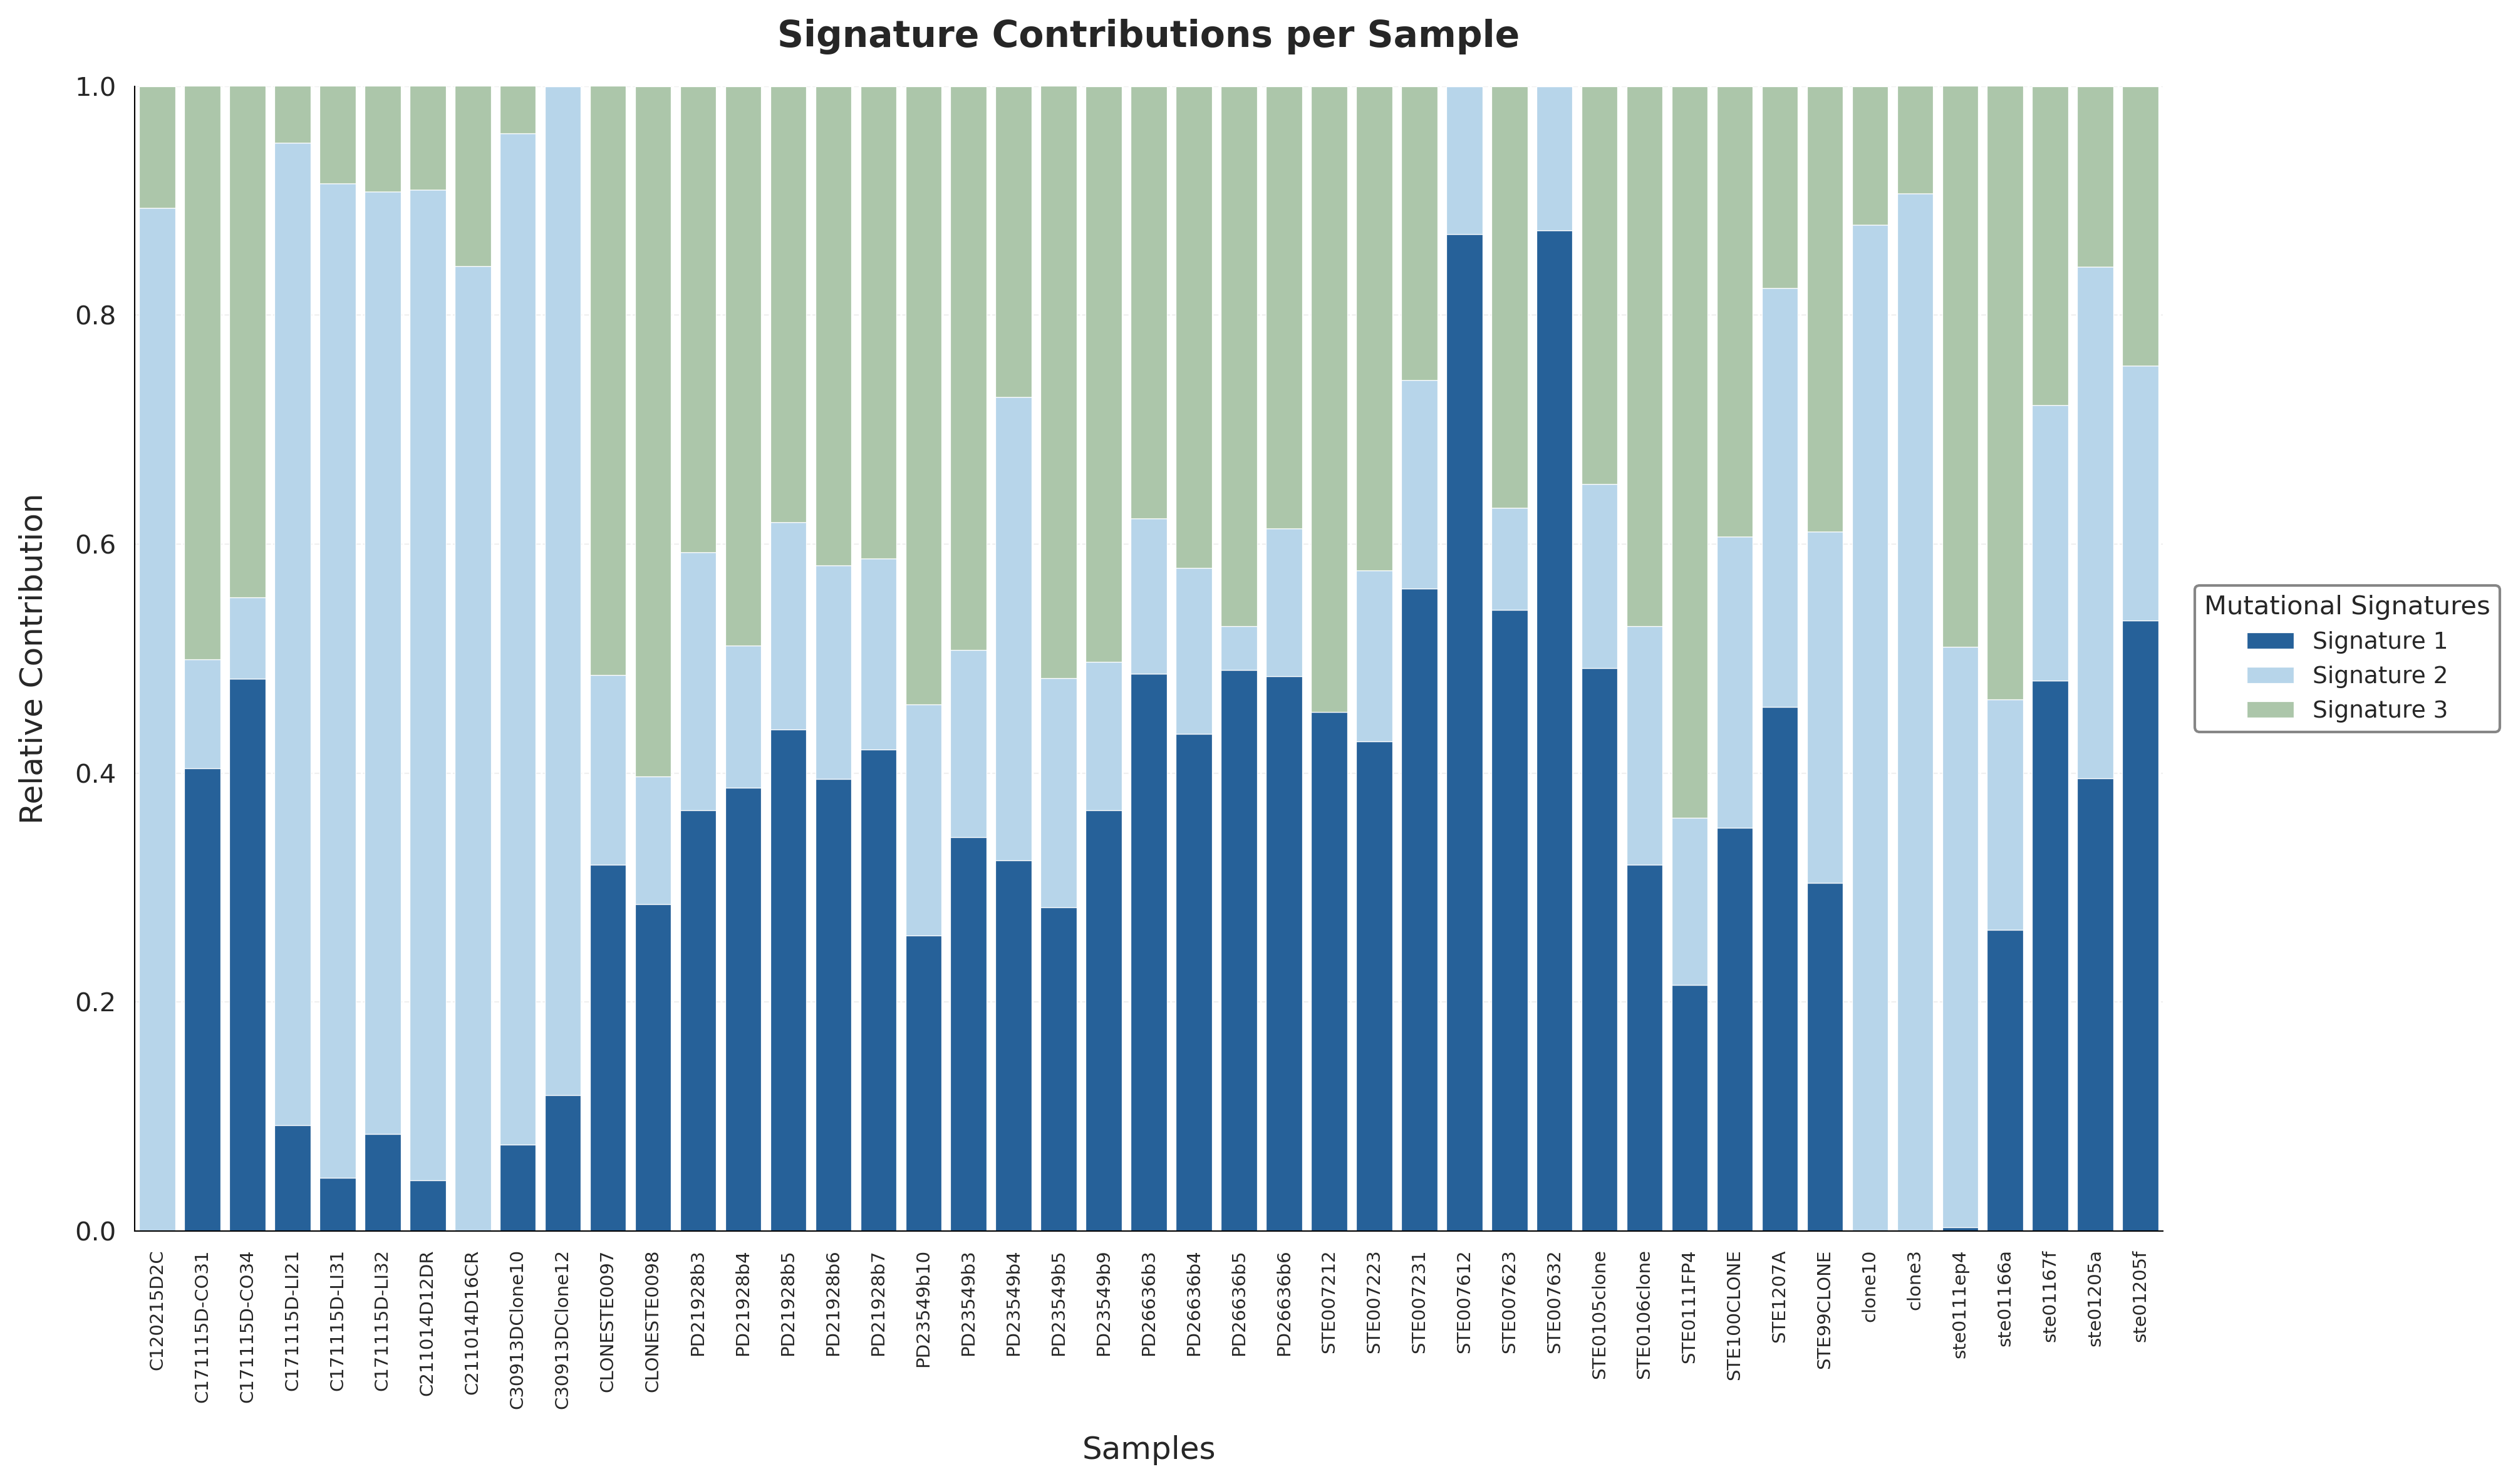

In [7]:
py_mutation.signature_stacked_bar_chart(
    ref_genome="/home/victor/.local/share/Trash/files/PyMut/data/references/hs37d5.fa"
)


### Panel E: Donut Plot

Donut chart showing the overall distribution of mutational signatures across the entire cohort. Unlike per-sample views, this reflects both activity and prevalence of each signature.

**Parameters:**

- `ref_genome`: Path to reference genome FASTA file (required)
- `n_signatures`: Number of signatures to extract. Default: `3`
- `figsize`: Figure size. Default: `(8, 8)`
- `title`: Plot title. Default: `"Relative Contribution of Mutational Signatures"`

2026-10-13 14:46:35,819 | INFO | pyMut.core | Generating signature donut plot...
2026-10-13 14:46:41,432 | INFO | pyMut.analysis.mutational_signature | NMF signature extraction completed in 0.40 seconds
2026-10-13 14:46:41,444 | INFO | pyMut.visualizations.mutational_signature_analysis | Generating signature donut plot...
2026-10-13 14:46:41,488 | INFO | pyMut.visualizations.mutational_signature_analysis | Signature donut plot rendered in 0.04s
2026-10-13 14:46:41,489 | INFO | pyMut.core | Signature donut plot generated in 5.67 seconds


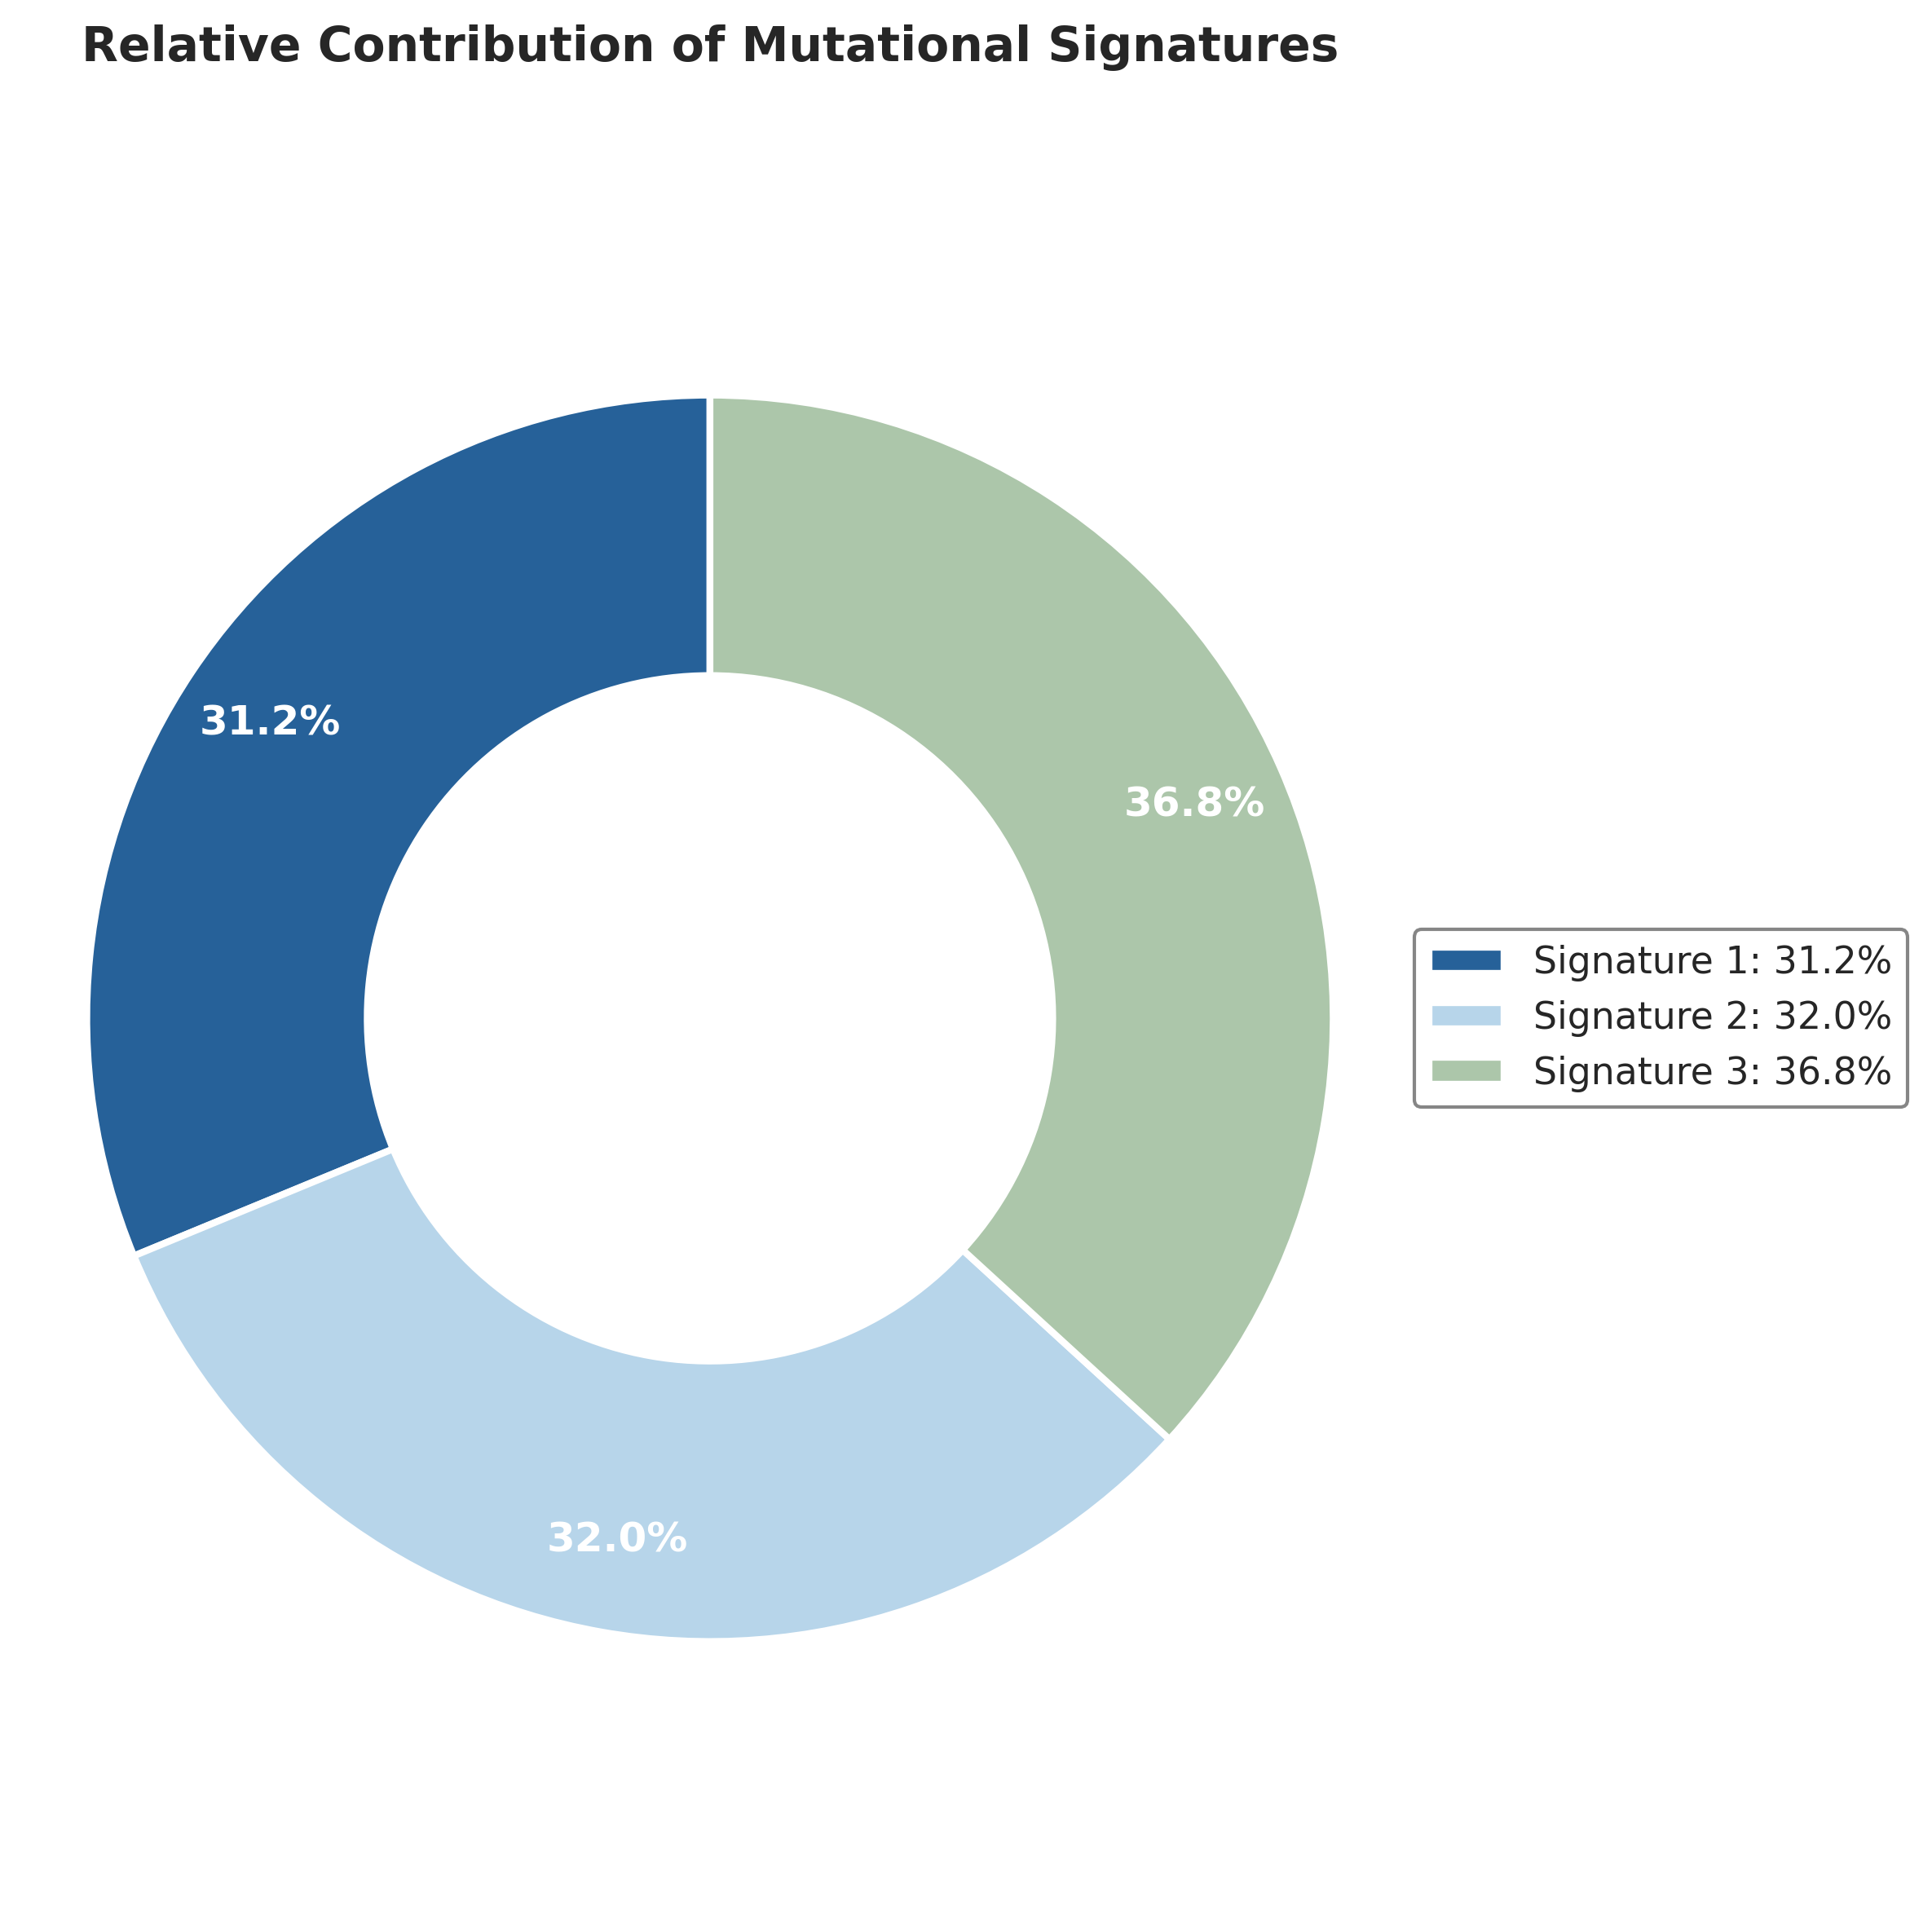

In [8]:
py_mutation.signature_donut_plot(
    ref_genome="/home/victor/.local/share/Trash/files/PyMut/data/references/hs37d5.fa"
)
